In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/policies_clean.csv")
train_ids = pd.read_csv("../data/processed/train_ids.csv")["IDpol"]
train = df[df["IDpol"].isin(train_ids)].reset_index(drop=True)
# replace the old size assert
assert len(train) == len(train_ids) and train["IDpol"].is_unique
OVERALL = train["ClaimNb"].sum() / train["Exposure"].sum()
print("overall frequency:", round(OVERALL, 4))

def freq_table(d, col, bins=None):
    key = d[col] if bins is None else pd.cut(d[col], bins)
    t = d.groupby(key, observed=True).agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        claims=("ClaimNb", "sum"),
    )
    assert t["policies"].sum() == len(d), f"{col}: rows lost in binning"
    t["exposure_share"] = t["exposure"] / t["exposure"].sum()
    t["freq"] = t["claims"] / t["exposure"]            # sum/sum
    t["relativity"] = t["freq"] / OVERALL              # 1.0 = average risk
    t["thin"] = np.where(t["claims"] < 100, "<100 claims", "")
    return t.round(4)

def plot_freq(t, title):
    fig, ax1 = plt.subplots(figsize=(8, 3.5))
    x = np.arange(len(t))
    ax1.bar(x, t["exposure_share"], color="lightgrey")
    ax1.set_ylabel("exposure share")
    ax1.set_xticks(x)
    ax1.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right")
    ax2 = ax1.twinx()
    ax2.plot(x, t["freq"], "o-", color="tab:red")
    ax2.axhline(OVERALL, ls="--", color="k", lw=0.8)
    ax2.set_ylabel("frequency")
    ax1.set_title(title)
    plt.tight_layout()
    plt.show()

overall frequency: 0.1009


         policies    share
ClaimNb                   
0          514224  0.94975
1           25728  0.04752
2            1398  0.00258
3              66  0.00012
4               7  0.00001
5               2  0.00000
6               1  0.00000
8               1  0.00000
9               1  0.00000
11              3  0.00001
16              1  0.00000 

ClaimNb mean=0.0533  var=0.0579  var/mean=1.09

count    541432.000
mean          0.528
std           0.364
min           0.003
25%           0.170
50%           0.490
75%           0.990
max           1.000
Name: Exposure, dtype: float64 

             policies     exposure  claims  exposure_share    freq  \
Exposure                                                             
(0.0, 0.1]     102054    6025.8841    2785          0.0211  0.4622   
(0.1, 0.25]     76054   13925.4600    2890          0.0487  0.2075   
(0.25, 0.5]    105108   41132.7700    5212          0.1439  0.1267   
(0.5, 0.75]     73967   46836.6700    4822          0.16

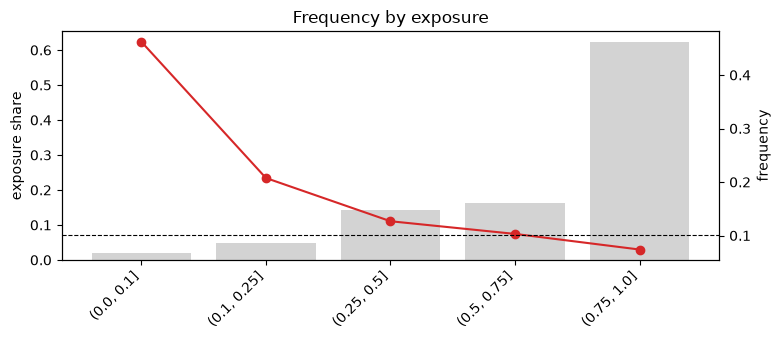

In [2]:
# Claim counts
cnt = train["ClaimNb"].value_counts().sort_index()
print(pd.DataFrame({"policies": cnt, "share": (cnt / len(train)).round(5)}), "\n")

# Overdispersion check: Poisson has variance = mean (per unit of exposure)
m, v = train["ClaimNb"].mean(), train["ClaimNb"].var()
print(f"ClaimNb mean={m:.4f}  var={v:.4f}  var/mean={v/m:.2f}\n")

# Exposure
print(train["Exposure"].describe().round(3), "\n")
t = freq_table(train, "Exposure", [0, 0.1, 0.25, 0.5, 0.75, 1.0])
print(t, "\n")          # freq should be ~flat if claims scale with exposure
plot_freq(t, "Frequency by exposure")

=== DrivAge ===
           policies    exposure  claims  exposure_share    freq  relativity  \
DrivAge                                                                       
(17, 21]       9142   3565.3844     804          0.0125  0.2255      2.2353   
(21, 25]      22066   9411.1526    1477          0.0329  0.1569      1.5557   
(25, 30]      52390  23229.5953    2464          0.0813  0.1061      1.0514   
(30, 40]     135715  66907.1300    6023          0.2341  0.0900      0.8923   
(40, 50]     131719  70085.3448    7270          0.2452  0.1037      1.0282   
(50, 60]     107984  60533.3941    5826          0.2118  0.0962      0.9540   
(60, 70]      50919  30533.5346    2853          0.1068  0.0934      0.9262   
(70, 100]     31497  21529.1684    2115          0.0753  0.0982      0.9738   

          thin  
DrivAge         
(17, 21]        
(21, 25]        
(25, 30]        
(30, 40]        
(40, 50]        
(50, 60]        
(60, 70]        
(70, 100]        



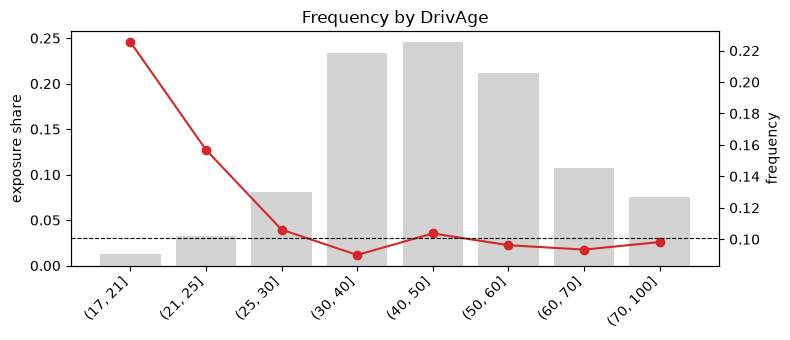

=== VehAge ===
           policies    exposure  claims  exposure_share    freq  relativity  \
VehAge                                                                        
(-1, 0]       45992  13195.9483    4106          0.0462  0.3112      3.0843   
(0, 1]        57020  26177.9624    2331          0.0916  0.0890      0.8826   
(1, 2]        47155  23652.5657    2215          0.0828  0.0936      0.9283   
(2, 5]       105951  57648.8946    5414          0.2017  0.0939      0.9309   
(5, 10]      136831  78933.2261    7838          0.2762  0.0993      0.9843   
(10, 15]     107014  62022.4432    5349          0.2170  0.0862      0.8549   
(15, 100]     41469  24163.6638    1579          0.0845  0.0653      0.6477   

          thin  
VehAge          
(-1, 0]         
(0, 1]          
(1, 2]          
(2, 5]          
(5, 10]         
(10, 15]        
(15, 100]        



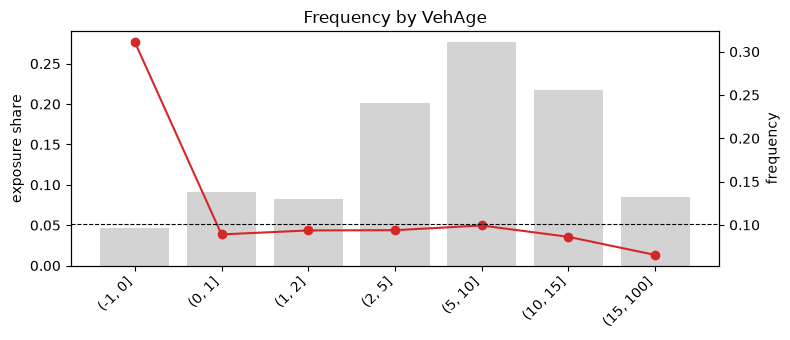

=== BonusMalus ===
            policies     exposure  claims  exposure_share    freq  relativity  \
BonusMalus                                                                      
(49, 50]      306711  179668.6730   14398          0.6287  0.0801      0.7943   
(50, 60]       75316   38102.2302    3620          0.1333  0.0950      0.9418   
(60, 70]       45486   21108.2093    2960          0.0739  0.1402      1.3900   
(70, 80]       49445   21202.2091    2707          0.0742  0.1277      1.2656   
(80, 100]      58216   22845.1665    4085          0.0799  0.1788      1.7725   
(100, 150]      6076    2784.9459    1018          0.0097  0.3655      3.6234   
(150, 350]       182      83.2700      44          0.0003  0.5284      5.2377   

                   thin  
BonusMalus               
(49, 50]                 
(50, 60]                 
(60, 70]                 
(70, 80]                 
(80, 100]                
(100, 150]               
(150, 350]  <100 claims   



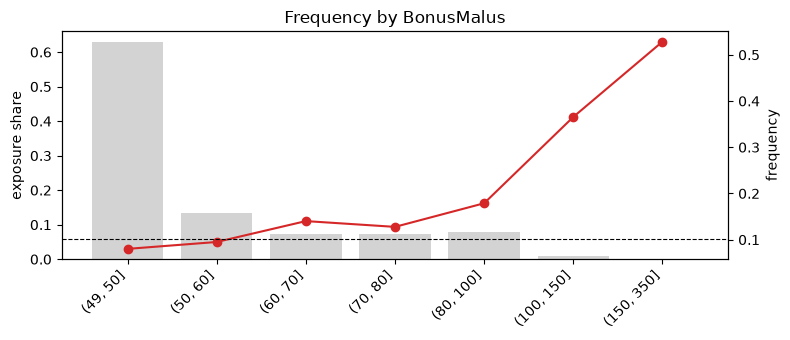

=== Density ===
               policies    exposure  claims  exposure_share    freq  \
Density                                                               
(0, 50]           84893  50713.5914    4114          0.1774  0.0811   
(50, 200]        123381  68619.9094    6199          0.2401  0.0903   
(200, 500]        88284  47730.9844    4629          0.1670  0.0970   
(500, 1500]      103005  52527.8856    5677          0.1838  0.1081   
(1500, 5000]     102514  48477.8912    5830          0.1696  0.1203   
(5000, 30000]     39355  17724.4422    2383          0.0620  0.1344   

               relativity thin  
Density                         
(0, 50]            0.8041       
(50, 200]          0.8955       
(200, 500]         0.9613       
(500, 1500]        1.0713       
(1500, 5000]       1.1921       
(5000, 30000]      1.3327        



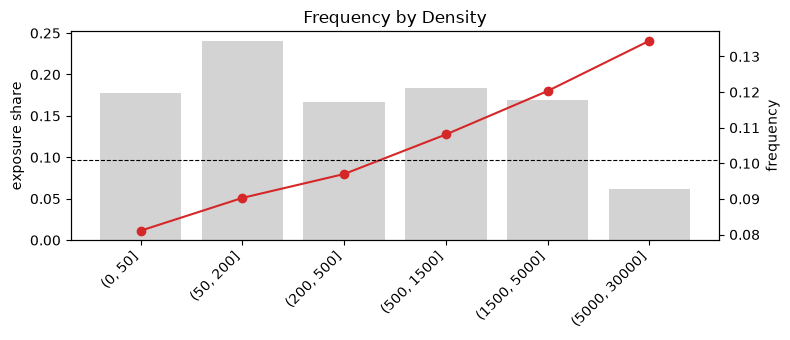

=== VehPower ===
          policies    exposure  claims  exposure_share    freq  relativity  \
VehPower                                                                     
4            91978  47927.0227    4536          0.1677  0.0946      0.9381   
5            99632  54359.7365    5798          0.1902  0.1067      1.0573   
6           119577  66101.4307    6746          0.2313  0.1021      1.0116   
7           115914  61910.1834    6083          0.2166  0.0983      0.9739   
8            37436  18096.6879    1531          0.0633  0.0846      0.8386   
9            24061  12249.2317    1424          0.0429  0.1163      1.1523   
10           25040  12275.0376    1399          0.0430  0.1140      1.1297   
11           14505   6668.7239     695          0.0233  0.1042      1.0331   
12            6567   3016.3370     291          0.0106  0.0965      0.9563   
13            2548   1284.0215     125          0.0045  0.0974      0.9650   
14            1867    921.2712      99         

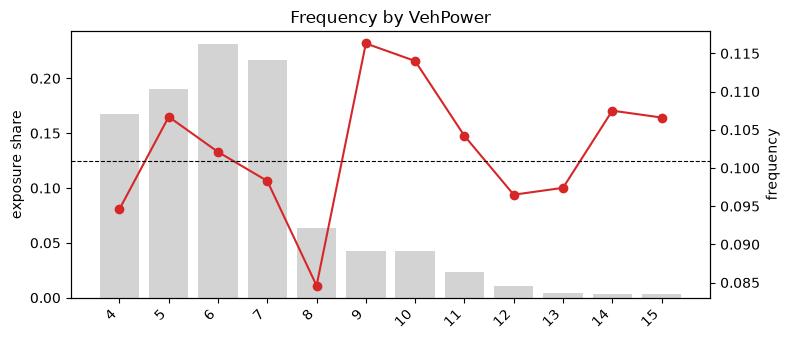

DrivAge 96-100:
         policies  exposure  claims  exposure_share    freq  relativity  \
DrivAge                                                                   
96             12     10.25       0          0.1848  0.0000      0.0000   
97              5      3.60       0          0.0649  0.0000      0.0000   
98              5      4.15       0          0.0748  0.0000      0.0000   
99             51     35.75       5          0.6444  0.1399      1.3864   
100             3      1.73       0          0.0312  0.0000      0.0000   

                thin  
DrivAge               
96       <100 claims  
97       <100 claims  
98       <100 claims  
99       <100 claims  
100      <100 claims   

BonusMalus == 50 share of exposure: 0.629


In [3]:
specs = {
    "DrivAge":    [17, 21, 25, 30, 40, 50, 60, 70, 100],
    "VehAge":     [-1, 0, 1, 2, 5, 10, 15, 100],
    "BonusMalus": [49, 50, 60, 70, 80, 100, 150, 350],
    "Density":    [0, 50, 200, 500, 1500, 5000, 30000],
    "VehPower":   None,
}
for col, bins in specs.items():
    t = freq_table(train, col, bins)
    print(f"=== {col} ===")
    print(t, "\n")
    plot_freq(t, f"Frequency by {col}")

# Spot checks on the odd values seen in cleaning
print("DrivAge 96-100:")
print(freq_table(train[train["DrivAge"] >= 96], "DrivAge"), "\n")
print("BonusMalus == 50 share of exposure:",
      round(train.loc[train["BonusMalus"] == 50, "Exposure"].sum() / train["Exposure"].sum(), 3))

=== VehGas ===
         policies     exposure  claims  exposure_share    freq  relativity  \
VehGas                                                                       
Regular    276475  149997.9200   15498          0.5248  0.1033      1.0242   
Diesel     264957  135796.7841   13334          0.4752  0.0982      0.9733   

        thin  
VehGas        
Regular       
Diesel         



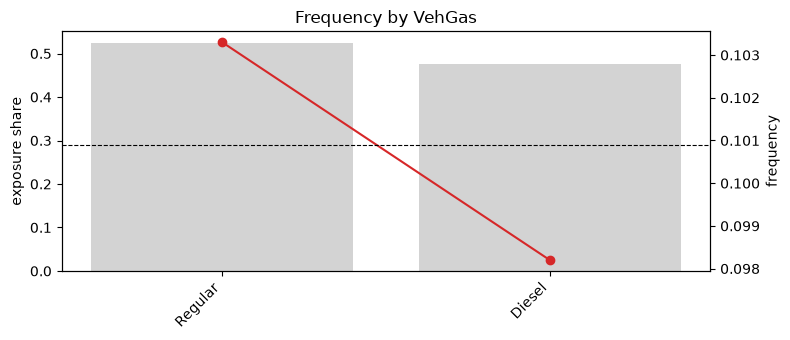

=== Area ===
      policies    exposure  claims  exposure_share    freq  relativity thin
Area                                                                       
F        14357   6520.7196     913          0.0228  0.1400      1.3879     
E       109412  50647.7653    6246          0.1772  0.1233      1.2224     
D       121184  61600.3140    6740          0.2155  0.1094      1.0846     
C       153017  83215.1147    7893          0.2912  0.0949      0.9402     
B        60467  34382.6320    3048          0.1203  0.0886      0.8787     
A        82995  49428.1585    3992          0.1729  0.0808      0.8006      



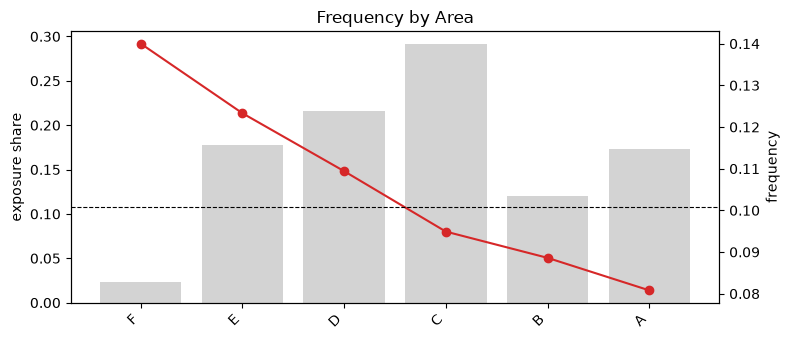

=== VehBrand ===
          policies    exposure  claims  exposure_share    freq  relativity  \
VehBrand                                                                     
B12         132604  51752.8880    7031          0.1811  0.1359      1.3467   
B11          10925   5502.8620     570          0.0193  0.1036      1.0268   
B5           27668  15904.3845    1600          0.0556  0.1006      0.9972   
B3           42674  22709.6990    2213          0.0795  0.0974      0.9659   
B4           20180  11049.3281    1065          0.0387  0.0964      0.9554   
B6           22746  12519.3434    1198          0.0438  0.0957      0.9485   
B10          14074   7511.2571     698          0.0263  0.0929      0.9211   
B13           9831   5472.4182     508          0.0191  0.0928      0.9202   
B1          130151  76099.7118    6951          0.2663  0.0913      0.9054   
B2          127318  75448.9723    6869          0.2640  0.0910      0.9024   
B14           3261   1823.8395     129         

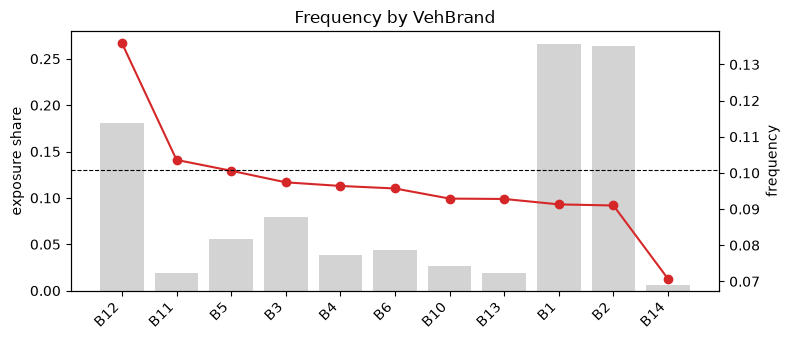

=== Region ===
                             policies    exposure  claims  exposure_share  \
Region                                                                      
Champagne-Ardenne                2384    942.4158     130          0.0033   
Corse                            3645   1435.3553     196          0.0050   
Ile-de-France                   55622  24057.2482    3193          0.0842   
Picardie                         6356   2833.3763     348          0.0099   
Limousin                         3659   1918.2062     216          0.0067   
Rhone-Alpes                     67447  36083.7148    4027          0.1263   
Alsace                           1738    945.5876     104          0.0033   
Provence-Alpes-Cotes-D'Azur     63428  28415.7855    3108          0.0994   
Languedoc-Roussillon            28584  11629.6497    1232          0.0407   
Franche-Comte                    1073    451.2356      47          0.0016   
Bourgogne                        8373   4008.2315     407    

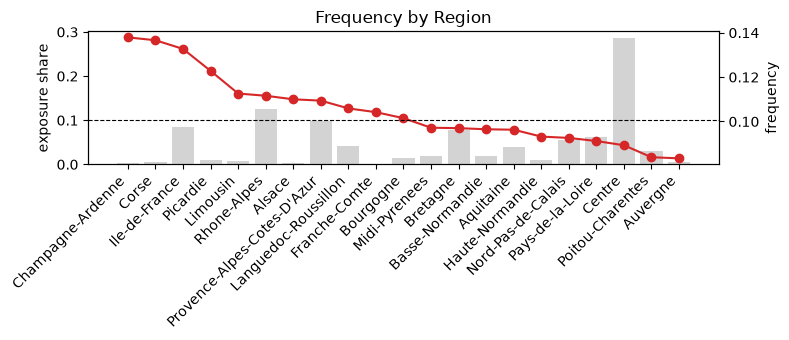

            DrivAge  VehAge  BonusMalus  VehPower  logDensity
DrivAge        1.00   -0.08       -0.57      0.04       -0.04
VehAge        -0.08    1.00        0.08     -0.00       -0.10
BonusMalus    -0.57    0.08        1.00     -0.07        0.14
VehPower       0.04   -0.00       -0.07      1.00       -0.01
logDensity    -0.04   -0.10        0.14     -0.01        1.00 

Area
A       27.0
B       71.0
C      222.0
D     1054.0
E     3744.0
F    27000.0
Name: Density, dtype: float64


In [4]:
for col in ["VehGas", "Area", "VehBrand", "Region"]:
    t = freq_table(train, col)
    print(f"=== {col} ===")
    print(t.sort_values("freq", ascending=False), "\n")
    plot_freq(t.sort_values("freq", ascending=False), f"Frequency by {col}")

# Are predictors redundant? (matters for GLM coefficients)
print(train[["DrivAge", "VehAge", "BonusMalus", "VehPower", "logDensity"]]
      .corr(method="spearman").round(2), "\n")
print(train.groupby("Area")["Density"].median().round(0))

In [5]:
# 1) is the VehAge-0 spike just a short-exposure effect?
age = train["VehAge"].eq(0).map({True: "age0", False: "age1+"})
band = pd.cut(train["Exposure"], [0, 0.25, 0.75, 1.0]).astype(str)
train["Cell"] = age + " | " + band
print(freq_table(train, "Cell"), "\n")

# 2) is B12 a new-car effect?
print(pd.crosstab(train["VehAge"] == 0, train["VehBrand"] == "B12", normalize="index").round(3), "\n")
print(freq_table(train[train["VehAge"] > 0], "VehBrand").sort_values("freq", ascending=False).head(3), "\n")

# 3) is Area just binned Density?
print(train.groupby("Area")["Density"].agg(["min", "max"]))

                      policies     exposure  claims  exposure_share    freq  \
Cell                                                                          
age0 | (0.0, 0.25]       26478    2418.9383    2089          0.0085  0.8636   
age0 | (0.25, 0.75]      15940    7685.8600    1646          0.0269  0.2142   
age0 | (0.75, 1.0]        3574    3091.1500     371          0.0108  0.1200   
age1+ | (0.0, 0.25]     151630   17532.4058    3586          0.0613  0.2045   
age1+ | (0.25, 0.75]    163135   80283.5800    8388          0.2809  0.1045   
age1+ | (0.75, 1.0]     180675  174782.7700   12752          0.6116  0.0730   

                      relativity thin  
Cell                                   
age0 | (0.0, 0.25]        8.5604       
age0 | (0.25, 0.75]       2.1228       
age0 | (0.75, 1.0]        1.1897       
age1+ | (0.0, 0.25]       2.0274       
age1+ | (0.25, 0.75]      1.0356       
age1+ | (0.75, 1.0]       0.7232        

VehBrand  False  True 
VehAge                